# Feedback Prize: Evaluating Student Writing
## Token Classification & Discourse Argumentation Pipeline (Longformer-4096)
### Modular Native PyTorch Architecture with AMP (FP16), Global Attention, and Macro-F1 Evaluation

---
This notebook implements an end-to-end, native PyTorch training and evaluation pipeline for discourse element extraction from student essays:
- **Backbone**: `allenai/longformer-base-4096` with full-length sequence processing (up to 4096 tokens).
- **Attention Configuration**: Sliding window localized attention with global attention placed on `<s>` (token index 0).
- **Optimization**: Native PyTorch mixed precision (`torch.amp`), gradient accumulation (effective batch size = 16), gradient clipping, and linear warmup learning rate decay.
- **Evaluation**: Official Kaggle Feedback Prize Macro-F1 metric utilizing word-level IoU $\ge 0.5$ overlap matching across all 7 discourse classes.

## 1. Environment & Package Installation

In [1]:
%pip install -q transformers sentencepiece protobuf datasets accelerate scikit-learn pandas numpy tqdm

## 2. Imports, Device Detection & Deterministic Seeding

In [2]:
import os
import gc
import sys
import time
import math
import random
from pathlib import Path
from dataclasses import dataclass, field
from typing import List, Dict, Tuple, Any, Optional, Union

import numpy as np
import pandas as pd
from tqdm.auto import tqdm
from sklearn.model_selection import train_test_split

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torch.optim.lr_scheduler import LambdaLR
from transformers import (
    AutoTokenizer,
    AutoConfig,
    AutoModelForTokenClassification,
    PreTrainedTokenizerFast
)

def set_deterministic_seed(seed: int = 42) -> None:
    '''Enforces deterministic execution across CPU, CUDA, and random generators.'''
    random.seed(seed)
    os.environ['PYTHONHASHSEED'] = str(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed(seed)
        torch.cuda.manual_seed_all(seed)
        torch.backends.cudnn.deterministic = True
        torch.backends.cudnn.benchmark = False

set_deterministic_seed(42)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Active Compute Device: {device}')
if torch.cuda.is_available():
    print(f'GPU Model:            {torch.cuda.get_device_name(0)}')
    print(f'Total VRAM:           {torch.cuda.get_device_properties(0).total_memory / (1024**3):.2f} GB')
else:
    print('Running in CPU execution mode.')

Active Compute Device: cuda
GPU Model:            Tesla T4
Total VRAM:           14.56 GB


## 3. Pipeline Configuration & Discourse Schema

In [3]:
@dataclass
class LongformerPipelineConfig:
    '''Central configuration for Longformer training and inference.'''
    # Model architecture
    model_checkpoint: str = 'allenai/longformer-base-4096'
    max_seq_length: int = 2048
    num_classes: int = 15
    dropout_prob: float = 0.1

    # Optimization & Hardware
    seed: int = 42
    epochs: int = 2
    train_batch_size: int = 2
    eval_batch_size: int = 2
    gradient_accumulation_steps: int = 8
    learning_rate: float = 3.0e-5
    weight_decay: float = 0.01
    warmup_ratio: float = 0.1
    max_gradient_norm: float = 1.0
    adam_epsilon: float = 1e-6

    # Loss & Post-Processing thresholds
    o_class_loss_weight: float = 0.40
    o_decision_threshold: float = 0.45

    # Data handling & Persistence
    max_essays_sample: Optional[int] = None
    validation_ratio: float = 0.15
    artifact_directory: str = 'outputs_longformer'
    checkpoint_filename: str = 'best_longformer_weights.pt'
    eval_subset_limit: int = 200
    dataloader_workers: int = field(default_factory=lambda: 2 if os.name != 'nt' else 0)

    @property
    def checkpoint_path(self) -> Path:
        return Path(self.artifact_directory) / self.checkpoint_filename


class DiscourseSchema:
    '''Discourse classification taxonomy and span length constraints.'''

    DISCOURSE_TYPES: Tuple[str, ...] = (
        'Lead',
        'Position',
        'Claim',
        'Counterclaim',
        'Rebuttal',
        'Evidence',
        'Concluding Statement'
    )

    MINIMUM_SPAN_LENGTHS: Dict[str, int] = {
        'Lead': 3,
        'Position': 3,
        'Claim': 3,
        'Counterclaim': 3,
        'Rebuttal': 3,
        'Evidence': 5,
        'Concluding Statement': 4
    }

    # Construct 15-class BIO tag sequence
    TAGS: List[str] = ['O'] + [
        f'{prefix}-{dtype}'
        for dtype in DISCOURSE_TYPES
        for prefix in ('B', 'I')
    ]

    LABEL2ID: Dict[str, int] = {tag: idx for idx, tag in enumerate(TAGS)}
    ID2LABEL: Dict[int, str] = {idx: tag for idx, tag in enumerate(TAGS)}

config = LongformerPipelineConfig()
print(f'BIO Label Schema ({len(DiscourseSchema.TAGS)} total classes):')
print(DiscourseSchema.TAGS)

BIO Label Schema (15 total classes):
['O', 'B-Lead', 'I-Lead', 'B-Position', 'I-Position', 'B-Claim', 'I-Claim', 'B-Counterclaim', 'I-Counterclaim', 'B-Rebuttal', 'I-Rebuttal', 'B-Evidence', 'I-Evidence', 'B-Concluding Statement', 'I-Concluding Statement']


## 4. Dataset Path Resolution & Essay Reading

In [4]:
import os
from pathlib import Path
from dotenv import load_dotenv

# 1. Define project root (one level up from the notebooks folder)
ROOT_DIR = Path(os.getcwd()).parent
DATA_RAW_DIR = ROOT_DIR / "data" / "raw"

# 2. Create folders
os.makedirs(DATA_RAW_DIR, exist_ok=True)

# 3. Load credentials from .env (needed for downloading data)
load_dotenv(ROOT_DIR / ".env")

print(f"✅ Project root: {ROOT_DIR}")
print(f"✅ Data will be stored here: {DATA_RAW_DIR}")

✅ Project root: /
✅ Data will be stored here: /data/raw


In [5]:
import kagglehub
import shutil
import pandas as pd

from google.colab import userdata

def setup_project_data(output_path):
    if (output_path / "train.csv").exists():
        print("✅ Data already downloaded.")
        return
    print("⏳ Downloading from Kaggle...")
    os.environ["KAGGLE_USERNAME"] = userdata.get('KAGGLE_USERNAME')
    os.environ["KAGGLE_KEY"] = userdata.get('KAGGLE_KEY')

    try:
        tmp_cache = kagglehub.competition_download('feedback-prize-2021')
    except Exception as e:
        print(f"❌ Download failed: {e}")
        print("Check that you've accepted the competition rules on Kaggle and that .env has valid credentials")
        raise
    for item in os.listdir(tmp_cache):
        src = os.path.join(tmp_cache, item)
        dst = output_path / item
        if os.path.isdir(src):
            shutil.copytree(src, dst, dirs_exist_ok=True)
        else:
            shutil.copy2(src, dst)
    print("🚀 Download complete!")

setup_project_data(DATA_RAW_DIR)
train_df = pd.read_csv(DATA_RAW_DIR / "train.csv")
print(f"📊 Rows loaded: {len(train_df)}")

⏳ Downloading from Kaggle...


100%|██████████| 32.4M/32.4M [00:01<00:00, 23.2MB/s]

Extracting files...


🚀 Download complete!
📊 Rows loaded: 144293


In [6]:
def locate_dataset_resources() -> Tuple[Path, Path]:
    '''Dynamically locates train.csv and train text folder across directory structures.'''
    candidate_csv_locations = [
        Path("data/raw/train.csv"),
        Path("data/train.csv"),
        Path("train.csv"),
        Path("/content/data/raw/train.csv"),
        Path("/content/data/train.csv"),
        Path("/content/train.csv"),
        Path("feedback-prize-2021/train.csv"),
        Path("../data/raw/train.csv"),
        Path("../data/train.csv")
    ]

    candidate_text_dirs = [
        Path("data/raw/train"),
        Path("data/train"),
        Path("train"),
        Path("/content/data/raw/train"),
        Path("/content/data/train"),
        Path("/content/train"),
        Path("feedback-prize-2021/train"),
        Path("../data/raw/train"),
        Path("../data/train")
    ]

    resolved_csv = next((p.resolve() for p in candidate_csv_locations if p.is_file()), None)
    resolved_txt_dir = next(
        (p.resolve() for p in candidate_text_dirs if p.is_dir() and any(p.iterdir())),
        None
    )

    if resolved_csv is None or resolved_txt_dir is None:
        raise FileNotFoundError(
            'Unable to find dataset. Ensure `train.csv` and `train/` text files exist.'
        )

    return resolved_csv, resolved_txt_dir


def read_essay_content(essay_identifier: str, text_directory: Union[str, Path]) -> str:
    '''Reads essay text file from storage.'''
    file_path = Path(text_directory) / f'{essay_identifier}.txt'
    with open(file_path, 'r', encoding='utf-8') as stream:
        return stream.read()

csv_file, text_directory = locate_dataset_resources()
print(f'CSV Path:       {csv_file}')
print(f'Text Directory: {text_directory}')

CSV Path:       /data/raw/train.csv
Text Directory: /data/raw/train


## 5. Text Alignment & Word-Level BIO Tagging

In [7]:
class AnnotationPreprocessor:
    '''Transforms raw character spans and prediction strings into word-level BIO tags.'''

    @staticmethod
    def align_word_labels(
        essay_id: str,
        raw_text: str,
        grouped_annotations: Dict[str, pd.DataFrame]
    ) -> Tuple[List[str], List[str]]:
        '''
        Splits raw text into whitespace-delimited tokens and assigns B-/I-/O tags
        based on the official predictionstring index mapping.
        '''
        words = raw_text.split()
        word_tags = ['O'] * len(words)

        if essay_id in grouped_annotations:
            essay_records = grouped_annotations[essay_id]
            for _, record in essay_records.iterrows():
                discourse_category = record['discourse_type']
                pred_str_indices = [
                    int(idx_str) for idx_str in str(record['predictionstring']).split()
                    if idx_str.isdigit()
                ]

                if not pred_str_indices:
                    continue

                # Mark start of discourse element
                first_idx = pred_str_indices[0]
                if first_idx < len(word_tags):
                    word_tags[first_idx] = f'B-{discourse_category}'

                # Mark continuation of discourse element
                for subsequent_idx in pred_str_indices[1:]:
                    if subsequent_idx < len(word_tags):
                        word_tags[subsequent_idx] = f'I-{discourse_category}'

        return words, word_tags

## 6. Native PyTorch Longformer Dataset with Global Attention Mask

In [40]:
class StudentDiscourseDataset(Dataset):
    '''
    Dataset wrapping student essays with Longformer token alignment and global attention masking.
    '''

    def __init__( einz,
        essay_ids: List[str],
        annotations_df: pd.DataFrame,
        tokenizer: PreTrainedTokenizerFast,
        text_dir: Path,
        max_seq_length: int = 2048
    ) -> None:
        einz.essay_ids = essay_ids
        einz.tokenizer = tokenizer
        einz.text_dir = Path(text_dir)
        einz.max_seq_length = max_seq_length

        # Pre-group annotations for O(1) indexed lookup per essay
        filtered_df = annotations_df[annotations_df['id'].isin(set(essay_ids))]
        einz.grouped_records: Dict[str, pd.DataFrame] = {
            essay_key: group for essay_key, group in filtered_df.groupby('id')
        }

    def __len__(self) -> int:
        return len(self.essay_ids)

    def __getitem__(self, index: int) -> Dict[str, torch.Tensor]:
        essay_id = self.essay_ids[index]
        essay_text = read_essay_content(essay_id, self.text_dir)

        words, word_bio_tags = AnnotationPreprocessor.align_word_labels(
            essay_id, essay_text, self.grouped_records
        )

        tokenized_inputs = self.tokenizer(
            words,
            is_split_into_words=True,
            truncation=True,
            max_length=self.max_seq_length,
            padding='max_length',
            return_tensors=None
        )

        word_ids = tokenized_inputs.word_ids()
        target_labels: List[int] = []
        previous_word_idx: Optional[int] = None

        for w_idx in word_ids:
            if w_idx is None:
                # Special tokens (<s>, </s>, <pad>) ignored in loss
                target_labels.append(-100)
            elif w_idx != previous_word_idx:
                # First subword token receives the ground truth entity label
                assigned_tag = word_bio_tags[w_idx] if w_idx < len(word_bio_tags) else 'O'
                target_labels.append(DiscourseSchema.LABEL2ID[assigned_tag])
            else:
                # Subsequent subword continuation tokens are masked out
                target_labels.append(-100)
            previous_word_idx = w_idx

        # Global attention mask: 1 on <s> (index 0) for document-wide pooling, 0 elsewhere
        global_attention = [0] * len(tokenized_inputs['input_ids'])
        global_attention[0] = 1

        return {
            'input_ids': torch.tensor(tokenized_inputs['input_ids'], dtype=torch.long),
            'attention_mask': torch.tensor(tokenized_inputs['attention_mask'], dtype=torch.long),
            'global_attention_mask': torch.tensor(global_attention, dtype=torch.long),
            'labels': torch.tensor(target_labels, dtype=torch.long)
        }

## 7. Longformer Token Classification Architecture

In [9]:
class LongformerTokenClassifier(nn.Module):
    '''Longformer backbone configured for token classification.'''

    def __init__(
        self,
        model_checkpoint: str = 'allenai/longformer-base-4096',
        num_labels: int = 15,
        dropout_prob: float = 0.1
    ) -> None:
        super().__init__()
        self.config = AutoConfig.from_pretrained(model_checkpoint)
        self.config.num_labels = num_labels
        self.config.hidden_dropout_prob = dropout_prob
        self.config.attention_probs_dropout_prob = dropout_prob

        self.transformer = AutoModelForTokenClassification.from_pretrained(
            model_checkpoint,
            config=self.config,
            torch_dtype=torch.float32
        )

    def forward(
        self,
        input_ids: torch.Tensor,
        attention_mask: torch.Tensor,
        global_attention_mask: Optional[torch.Tensor] = None,
        labels: Optional[torch.Tensor] = None
    ) -> Any:
        return self.transformer(
            input_ids=input_ids,
            attention_mask=attention_mask,
            global_attention_mask=global_attention_mask,
            labels=labels,
            return_dict=True
        )

## 8. Official Competition Metric Engine (Span IoU >= 0.5 Macro-F1)

In [10]:
class FeedbackMetricEngine:
    '''Official Kaggle competition evaluation metric using IoU >= 0.5 overlap.'''

    @staticmethod
    def calculate_span_iou(pred_interval: Tuple[int, int], true_interval: Tuple[int, int]) -> float:
        '''Computes 1D word-level Intersection-over-Union (IoU).'''
        p_start, p_end = pred_interval
        t_start, t_end = true_interval

        intersection = max(0, min(p_end, t_end) - max(p_start, t_start) + 1)
        union = max(p_end, t_end) - min(p_start, t_start) + 1
        return float(intersection / union) if union > 0 else 0.0

    @classmethod
    def compute_macro_f1(
        cls,
        predictions_df: pd.DataFrame,
        ground_truth_df: pd.DataFrame,
        iou_threshold: float = 0.5
    ) -> Tuple[float, pd.DataFrame]:
        '''Calculates Macro-F1 across all 7 discourse classes.'''
        per_class_stats = []
        class_f1_scores = []

        all_essay_ids = set()
        if not ground_truth_df.empty and 'id' in ground_truth_df:
            all_essay_ids.update(ground_truth_df['id'].unique())
        if not predictions_df.empty and 'id' in predictions_df:
            all_essay_ids.update(predictions_df['id'].unique())

        for discourse_type in DiscourseSchema.DISCOURSE_TYPES:
            pred_sub = (
                predictions_df[predictions_df['discourse_type'] == discourse_type]
                if not predictions_df.empty and 'discourse_type' in predictions_df
                else pd.DataFrame()
            )
            gt_sub = (
                ground_truth_df[ground_truth_df['discourse_type'] == discourse_type]
                if not ground_truth_df.empty and 'discourse_type' in ground_truth_df
                else pd.DataFrame()
            )

            pred_by_essay = dict(tuple(pred_sub.groupby('id'))) if not pred_sub.empty else {}
            gt_by_essay = dict(tuple(gt_sub.groupby('id'))) if not gt_sub.empty else {}

            tp, fp, fn = 0, 0, 0

            for essay_id in all_essay_ids:
                p_rows = pred_by_essay.get(essay_id, pd.DataFrame())
                g_rows = gt_by_essay.get(essay_id, pd.DataFrame())

                p_spans = []
                if not p_rows.empty and 'predictionstring' in p_rows:
                    for raw_ps in p_rows['predictionstring'].values:
                        tokens = [int(x) for x in str(raw_ps).split() if x.isdigit()]
                        if tokens:
                            p_spans.append((tokens[0], tokens[-1]))

                g_spans = []
                if not g_rows.empty and 'predictionstring' in g_rows:
                    for raw_ps in g_rows['predictionstring'].values:
                        tokens = [int(x) for x in str(raw_ps).split() if x.isdigit()]
                        if tokens:
                            g_spans.append((tokens[0], tokens[-1]))

                matched_ground_truths = set()
                for pred_span in p_spans:
                    highest_iou = 0.0
                    best_match_idx = -1

                    for gt_idx, gt_span in enumerate(g_spans):
                        if gt_idx in matched_ground_truths:
                            continue
                        iou = cls.calculate_span_iou(pred_span, gt_span)
                        if iou > highest_iou:
                            highest_iou = iou
                            best_match_idx = gt_idx

                    if highest_iou >= iou_threshold:
                        tp += 1
                        matched_ground_truths.add(best_match_idx)
                    else:
                        fp += 1

                fn += len(g_spans) - len(matched_ground_truths)

            precision = tp / (tp + fp) if (tp + fp) > 0 else 0.0
            recall = tp / (tp + fn) if (tp + fn) > 0 else 0.0
            f1 = (2 * precision * recall) / (precision + recall) if (precision + recall) > 0 else 0.0
            class_f1_scores.append(f1)

            per_class_stats.append({
                'Discourse Type': discourse_type,
                'Precision': round(precision, 4),
                'Recall': round(recall, 4),
                'F1-Score': round(f1, 4),
                'TP': tp,
                'FP': fp,
                'FN': fn,
                'Ground Truth Spans': len(gt_sub),
                'Predicted Spans': len(pred_sub)
            })

        overall_macro_f1 = float(np.mean(class_f1_scores)) if class_f1_scores else 0.0
        summary_table = pd.DataFrame(per_class_stats)
        return overall_macro_f1, summary_table

## 9. Inference Span Extractor & Sequence Decoder

In [11]:
class DiscourseSpanDecoder:
    '''Decodes token logits into contiguous discourse spans.'''

    @staticmethod
    def extract_spans_from_text(
        text: str,
        model: nn.Module,
        tokenizer: PreTrainedTokenizerFast,
        device: torch.device,
        max_seq_length: int = 2048,
        o_threshold: float = 0.45,
        min_length_constraints: Optional[Dict[str, int]] = None
    ) -> List[Dict[str, Any]]:
        '''Runs model inference on raw text and groups BIO tokens into valid spans.'''
        if min_length_constraints is None:
            min_length_constraints = DiscourseSchema.MINIMUM_SPAN_LENGTHS

        words = text.split()
        if not words:
            return []

        encoded = tokenizer(
            words,
            is_split_into_words=True,
            truncation=True,
            max_length=max_seq_length,
            padding='max_length',
            return_tensors='pt'
        )

        token_to_word_mapping = encoded.word_ids()
        input_ids = encoded['input_ids'].to(device)
        attention_mask = encoded['attention_mask'].to(device)

        global_mask = torch.zeros_like(attention_mask)
        global_mask[:, 0] = 1

        model.eval()
        with torch.no_grad():
            is_cuda = device.type == 'cuda'
            with torch.amp.autocast(device_type='cuda' if is_cuda else 'cpu', enabled=is_cuda):
                outputs = model(input_ids, attention_mask, global_attention_mask=global_mask)
                logits = outputs.logits[0]
                probabilities = torch.softmax(logits.float(), dim=-1).cpu().numpy()

        word_assigned_tags = ['O'] * len(words)
        word_confidences = [1.0] * len(words)
        visited_words = set()

        for token_pos, word_id in enumerate(token_to_word_mapping):
            if word_id is None or word_id in visited_words:
                continue
            if word_id < len(words):
                probs = probabilities[token_pos]
                if probs[0] < o_threshold:
                    selected_tag_idx = int(np.argmax(probs[1:])) + 1
                else:
                    selected_tag_idx = int(np.argmax(probs))

                word_assigned_tags[word_id] = DiscourseSchema.ID2LABEL[selected_tag_idx]
                word_confidences[word_id] = float(probs[selected_tag_idx])
            visited_words.add(word_id)

        extracted_spans: List[Dict[str, Any]] = []
        active_type: Optional[str] = None
        active_start: Optional[int] = None
        active_confidences: List[float] = []

        def push_span(c_type: str, start_idx: int, end_idx: int, confs: List[float]) -> None:
            span_length = end_idx - start_idx + 1
            if span_length >= min_length_constraints.get(c_type, 1):
                extracted_spans.append({
                    'type': c_type,
                    'start_word': start_idx,
                    'end_word': end_idx,
                    'text': ' '.join(words[start_idx : end_idx + 1]),
                    'confidence': float(np.mean(confs)) if confs else 1.0,
                    'predictionstring': ' '.join(str(idx) for idx in range(start_idx, end_idx + 1))
                })

        for word_idx, (tag, conf) in enumerate(zip(word_assigned_tags, word_confidences)):
            if tag.startswith('B-'):
                if active_type is not None and active_start is not None:
                    push_span(active_type, active_start, word_idx - 1, active_confidences)
                active_type = tag[2:]
                active_start = word_idx
                active_confidences = [conf]
            elif tag.startswith('I-'):
                incoming_type = tag[2:]
                if incoming_type == active_type and active_start is not None:
                    active_confidences.append(conf)
                else:
                    if active_type is not None and active_start is not None:
                        push_span(active_type, active_start, word_idx - 1, active_confidences)
                    active_type = incoming_type
                    active_start = word_idx
                    active_confidences = [conf]
            else:  # 'O'
                if active_type is not None and active_start is not None:
                    push_span(active_type, active_start, word_idx - 1, active_confidences)
                active_type = None
                active_start = None
                active_confidences = []

        if active_type is not None and active_start is not None:
            push_span(active_type, active_start, len(words) - 1, active_confidences)

        return extracted_spans

## 10. Modular Native PyTorch Longformer Trainer

In [12]:
class LongformerTrainer:
    '''
    Orchestrates native PyTorch mixed-precision training, gradient accumulation,
    checkpointing, validation, and official competition metric evaluation.
    '''

    def __init__(
        self,
        config: LongformerPipelineConfig,
        train_ids: List[str],
        val_ids: List[str],
        annotations_df: pd.DataFrame,
        text_dir: Path
    ) -> None:
        self.cfg = config
        self.train_ids = train_ids
        self.val_ids = val_ids
        self.annotations_df = annotations_df
        self.text_dir = text_dir

        # Hardware & Precision initialization
        self.device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
        self.use_cuda = self.device.type == 'cuda'
        self.scaler = torch.amp.GradScaler('cuda', enabled=self.use_cuda)

        os.makedirs(self.cfg.artifact_directory, exist_ok=True)

        # Tokenizer & Model
        self.tokenizer = AutoTokenizer.from_pretrained(
            self.cfg.model_checkpoint,
            add_prefix_space=True
        )
        self.model = LongformerTokenClassifier(
            model_checkpoint=self.cfg.model_checkpoint,
            num_labels=self.cfg.num_classes,
            dropout_prob=self.cfg.dropout_prob
        ).to(self.device)

        # Loss function with downweighted non-entity 'O' class
        class_weights = torch.ones(self.cfg.num_classes, dtype=torch.float32, device=self.device)
        class_weights[0] = float(self.cfg.o_class_loss_weight)
        self.loss_criterion = nn.CrossEntropyLoss(weight=class_weights, ignore_index=-100)

        # DataLoaders
        self.train_dataset = StudentDiscourseDataset(
            self.train_ids, self.annotations_df, self.tokenizer, self.text_dir, self.cfg.max_seq_length
        )
        self.val_dataset = StudentDiscourseDataset(
            self.val_ids, self.annotations_df, self.tokenizer, self.text_dir, self.cfg.max_seq_length
        )

        self.train_loader = DataLoader(
            self.train_dataset,
            batch_size=self.cfg.train_batch_size,
            shuffle=True,
            drop_last=True,
            num_workers=self.cfg.dataloader_workers,
            pin_memory=self.use_cuda
        )
        self.val_loader = DataLoader(
            self.val_dataset,
            batch_size=self.cfg.eval_batch_size,
            shuffle=False,
            num_workers=self.cfg.dataloader_workers,
            pin_memory=self.use_cuda
        )

        # Optimizer & Scheduler
        self.optimizer = torch.optim.AdamW(
            self.model.parameters(),
            lr=self.cfg.learning_rate,
            eps=self.cfg.adam_epsilon,
            weight_decay=self.cfg.weight_decay
        )

        total_training_steps = (len(self.train_loader) // self.cfg.gradient_accumulation_steps) * self.cfg.epochs
        warmup_steps = int(total_training_steps * self.cfg.warmup_ratio)

        def lr_schedule(step: int) -> float:
            if step < warmup_steps:
                return float(step) / float(max(1, warmup_steps))
            decay_steps = max(1, total_training_steps - warmup_steps)
            return max(0.0, float(total_training_steps - step) / float(decay_steps))

        self.scheduler = LambdaLR(self.optimizer, lr_schedule)
        self.history: Dict[str, List[float]] = {'train_loss': [], 'val_loss': []}

    def _execute_train_epoch(self, epoch_idx: int) -> float:
        '''Runs a single training epoch with AMP and gradient accumulation.'''
        self.model.train()
        accumulated_loss = 0.0
        self.optimizer.zero_grad()

        progress_bar = tqdm(
            self.train_loader,
            desc=f'Epoch {epoch_idx + 1}/{self.cfg.epochs} [Train]',
            leave=False
        )

        for step, batch in enumerate(progress_bar):
            input_ids = batch['input_ids'].to(self.device, non_blocking=True)
            attention_mask = batch['attention_mask'].to(self.device, non_blocking=True)
            global_attention_mask = batch['global_attention_mask'].to(self.device, non_blocking=True)
            labels = batch['labels'].to(self.device, non_blocking=True)

            with torch.amp.autocast(device_type='cuda' if self.use_cuda else 'cpu', enabled=self.use_cuda):
                outputs = self.model(
                    input_ids=input_ids,
                    attention_mask=attention_mask,
                    global_attention_mask=global_attention_mask
                )
                logits = outputs.logits
                loss = self.loss_criterion(
                    logits.view(-1, self.cfg.num_classes).float(),
                    labels.view(-1)
                )
                loss_scaled = loss / self.cfg.gradient_accumulation_steps

            if self.use_cuda:
                self.scaler.scale(loss_scaled).backward()
            else:
                loss_scaled.backward()

            accumulated_loss += loss.item()

            # Optimization boundary
            if (step + 1) % self.cfg.gradient_accumulation_steps == 0 or (step + 1) == len(self.train_loader):
                if self.use_cuda:
                    try:
                        self.scaler.unscale_(self.optimizer)
                        torch.nn.utils.clip_grad_norm_(self.model.parameters(), self.cfg.max_gradient_norm)
                        self.scaler.step(self.optimizer)
                        self.scaler.update()
                    except ValueError:
                        torch.nn.utils.clip_grad_norm_(self.model.parameters(), self.cfg.max_gradient_norm)
                        self.scaler.step(self.optimizer)
                        self.scaler.update()
                else:
                    torch.nn.utils.clip_grad_norm_(self.model.parameters(), self.cfg.max_gradient_norm)
                    self.optimizer.step()

                self.optimizer.zero_grad()
                self.scheduler.step()

            progress_bar.set_postfix({'batch_loss': f'{loss.item():.4f}'})

        return accumulated_loss / max(1, len(self.train_loader))

    def _execute_eval_epoch(self) -> float:
        '''Evaluates token classification loss on the validation split.'''
        self.model.eval()
        total_eval_loss = 0.0

        with torch.no_grad():
            for batch in tqdm(self.val_loader, desc='[Validation Loss]', leave=False):
                input_ids = batch['input_ids'].to(self.device, non_blocking=True)
                attention_mask = batch['attention_mask'].to(self.device, non_blocking=True)
                global_attention_mask = batch['global_attention_mask'].to(self.device, non_blocking=True)
                labels = batch['labels'].to(self.device, non_blocking=True)

                with torch.amp.autocast(device_type='cuda' if self.use_cuda else 'cpu', enabled=self.use_cuda):
                    outputs = self.model(
                        input_ids=input_ids,
                        attention_mask=attention_mask,
                        global_attention_mask=global_attention_mask
                    )
                    logits = outputs.logits
                    loss = self.loss_criterion(
                        logits.view(-1, self.cfg.num_classes).float(),
                        labels.view(-1)
                    )
                total_eval_loss += loss.item()

        return total_eval_loss / max(1, len(self.val_loader))

    def train(self) -> Dict[str, List[float]]:
        '''Full training procedure with model checkpointing.'''
        print('\n=======================================================')
        print(f'  Starting Longformer Training Pipeline ({self.cfg.epochs} Epochs)')
        print(f'  Device: {self.device} | Sequences: {self.cfg.max_seq_length} tokens')
        print(f'  Training Batches: {len(self.train_loader):,} | Validation Batches: {len(self.val_loader):,}')
        print('=======================================================\n')

        best_loss = float('inf')

        for epoch in range(self.cfg.epochs):
            start_time = time.time()
            train_loss = self._execute_train_epoch(epoch)
            val_loss = self._execute_eval_epoch()
            elapsed = time.time() - start_time

            self.history['train_loss'].append(train_loss)
            self.history['val_loss'].append(val_loss)

            print(
                f'[Epoch {epoch + 1:02d}/{self.cfg.epochs:02d}] '
                f'Train Loss: {train_loss:.4f} | '
                f'Val Loss: {val_loss:.4f} | '
                f'Time: {elapsed:.1f}s'
            )

            if val_loss < best_loss:
                best_loss = val_loss
                torch.save(self.model.state_dict(), self.cfg.checkpoint_path)
                print(f' -> Best checkpoint saved to: {self.cfg.checkpoint_path}')

        print(f'\nTraining complete. Lowest Validation Loss: {best_loss:.4f}')
        return self.history

    def evaluate_competition_macro_f1(self, num_essays: Optional[int] = None) -> Tuple[float, pd.DataFrame]:
        '''Runs inference across validation essays and evaluates official Macro-F1.'''
        target_sample_size = num_essays or min(self.cfg.eval_subset_limit, len(self.val_ids))
        selected_eval_ids = self.val_ids[:target_sample_size]

        print(f'\nEvaluating Competition Macro-F1 on {len(selected_eval_ids):,} validation essays...')

        if self.cfg.checkpoint_path.exists():
            self.model.load_state_dict(torch.load(self.cfg.checkpoint_path, map_location=self.device))
            print(f'Loaded optimal weights from: {self.cfg.checkpoint_path}')

        gt_eval_df = self.annotations_df[
            self.annotations_df['id'].isin(selected_eval_ids)
        ][['id', 'discourse_type', 'predictionstring']].reset_index(drop=True)

        prediction_rows: List[Dict[str, str]] = []

        for essay_id in tqdm(selected_eval_ids, desc='Generating Spans'):
            text = read_essay_content(essay_id, self.text_dir)
            predicted_spans = DiscourseSpanDecoder.extract_spans_from_text(
                text=text,
                model=self.model,
                tokenizer=self.tokenizer,
                device=self.device,
                max_seq_length=self.cfg.max_seq_length,
                o_threshold=self.cfg.o_decision_threshold
            )

            for sp in predicted_spans:
                prediction_rows.append({
                    'id': essay_id,
                    'discourse_type': sp['type'],
                    'predictionstring': sp['predictionstring']
                })

        pred_eval_df = pd.DataFrame(prediction_rows)
        macro_f1, breakdown_table = FeedbackMetricEngine.compute_macro_f1(
            predictions_df=pred_eval_df,
            ground_truth_df=gt_eval_df,
            iou_threshold=0.5
        )

        return macro_f1, breakdown_table

## 11. Data Loading, Splitting & Trainer Initialization

In [13]:
config = LongformerPipelineConfig()
set_deterministic_seed(config.seed)

csv_file, text_directory = locate_dataset_resources()
annotations_dataframe = pd.read_csv(csv_file)
unique_essay_identifiers = annotations_dataframe['id'].unique().tolist()

if config.max_essays_sample is not None and config.max_essays_sample < len(unique_essay_identifiers):
    random.seed(config.seed)
    unique_essay_identifiers = random.sample(unique_essay_identifiers, config.max_essays_sample)
    annotations_dataframe = annotations_dataframe[
        annotations_dataframe['id'].isin(unique_essay_identifiers)
    ].reset_index(drop=True)
    print(f'Sampled {len(unique_essay_identifiers)} essays for fast iteration.')

train_ids, val_ids = train_test_split(
    unique_essay_identifiers,
    test_size=config.validation_ratio,
    random_state=config.seed
)

print(f'Dataset split: {len(train_ids):,} train essays | {len(val_ids):,} validation essays')

trainer = LongformerTrainer(
    config=config,
    train_ids=train_ids,
    val_ids=val_ids,
    annotations_df=annotations_dataframe,
    text_dir=text_directory
)

Dataset split: 13,254 train essays | 2,340 validation essays


config.json:   0%|          | 0.00/694 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/899k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

...

pytorch_model.bin: downloading bytes:           |  0.00B            

model.safetensors: reconstructing file:   0%|          |  0.00B /  597MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/269 [00:00<?, ?it/s]

[transformers] LongformerForTokenClassification LOAD REPORT from: allenai/longformer-base-4096
Key                            | Status     | 
-------------------------------+------------+-
lm_head.bias                   | UNEXPECTED | 
lm_head.dense.weight           | UNEXPECTED | 
lm_head.dense.bias             | UNEXPECTED | 
lm_head.layer_norm.bias        | UNEXPECTED | 
lm_head.decoder.weight         | UNEXPECTED | 
lm_head.layer_norm.weight      | UNEXPECTED | 
longformer.pooler.dense.bias   | UNEXPECTED | 
longformer.pooler.dense.weight | UNEXPECTED | 
classifier.weight              | MISSING    | 
classifier.bias                | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


## 12. Run Model Training (AMP FP16 + Checkpointing)

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

file_path = '/content/drive/MyDrive/longformer_weights.pt'                  # your file path here

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
trainer.model.load_state_dict(torch.load(file_path, map_location=device))

<All keys matched successfully>

In [16]:
training_history = trainer.train()


  Starting Longformer Training Pipeline (2 Epochs)
  Device: cuda | Sequences: 2048 tokens
  Training Batches: 6,627 | Validation Batches: 1,170



Epoch 1/2 [Train]:   0%|          | 0/6627 [00:00<?, ?it/s]

[Validation Loss]:   0%|          | 0/1170 [00:00<?, ?it/s]

[Epoch 01/02] Train Loss: 0.8769 | Val Loss: 0.6366 | Time: 5403.6s
 -> Best checkpoint saved to: outputs_longformer/best_longformer_weights.pt


Epoch 2/2 [Train]:   0%|          | 0/6627 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7e5571612de0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7e5571612de0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/

[Validation Loss]:   0%|          | 0/1170 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7e5571612de0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7e5571612de0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/

[Epoch 02/02] Train Loss: 0.5780 | Val Loss: 0.5974 | Time: 5404.1s
 -> Best checkpoint saved to: outputs_longformer/best_longformer_weights.pt

Training complete. Lowest Validation Loss: 0.5974


In [52]:
torch.save(trainer.model.state_dict(), file_path)

## 13. Official Competition Macro-F1 Metric Evaluation

Evaluating validation set and generating performance visualization...

Evaluating Competition Macro-F1 on 200 validation essays...
Loaded optimal weights from: outputs_longformer/best_longformer_weights.pt


Generating Spans:   0%|          | 0/200 [00:00<?, ?it/s]


FINAL COMPETITION MACRO-F1 SCORE: 0.5793

Discourse Type Detailed Breakdown:


,Discourse Type,Precision,Recall,F1-Score,TP,FP,FN,Ground Truth Spans,Predicted Spans
0,Lead,0.6011,0.8359,0.6993,107,71,21,128,178
1,Position,0.5947,0.6818,0.6353,135,92,63,198,227
2,Claim,0.4772,0.5138,0.4948,335,367,317,652,702
3,Counterclaim,0.4576,0.6207,0.5268,54,64,33,87,118
4,Rebuttal,0.3273,0.5000,0.3956,36,74,36,72,110
5,Evidence,0.4945,0.5918,0.5388,361,369,249,610,730
6,Concluding Statement,0.6681,0.8933,0.7644,159,79,19,178,238


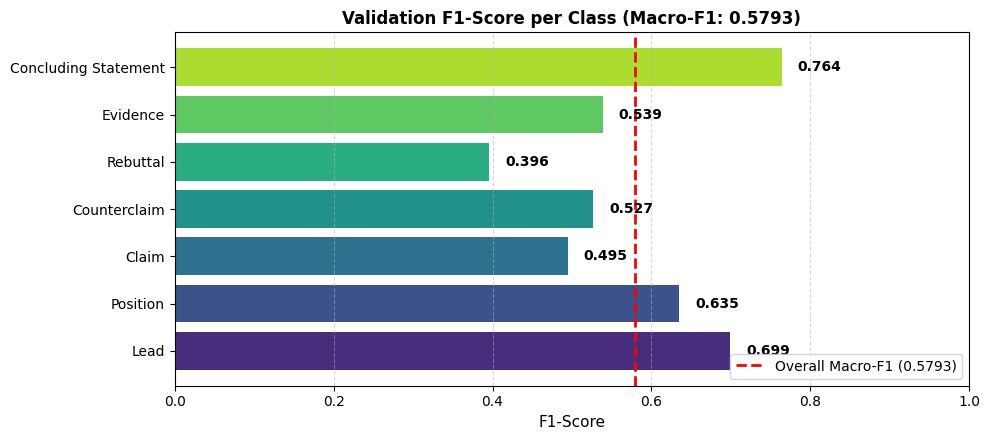

In [47]:
import matplotlib.pyplot as plt
import seaborn as sns

print("Evaluating validation set and generating performance visualization...")

# Run metric evaluation
macro_f1, detailed_df = trainer.evaluate_competition_macro_f1()

print("\n" + "=" * 85)
print(f"FINAL COMPETITION MACRO-F1 SCORE: {macro_f1:.4f}")
print("=" * 85 + "\n")

print("Discourse Type Detailed Breakdown:")
display(detailed_df)

# Plotting F1-Score Breakdown
plt.figure(figsize=(10, 4.5))
palette = sns.color_palette("viridis", len(detailed_df))
bars = plt.barh(detailed_df["Discourse Type"], detailed_df["F1-Score"], color=palette)
plt.title(f"Validation F1-Score per Class (Macro-F1: {macro_f1:.4f})", fontsize=12, fontweight="bold")
plt.xlabel("F1-Score", fontsize=11)
plt.xlim(0, 1.0)
plt.axvline(x=macro_f1, color="red", linestyle="--", linewidth=2, label=f"Overall Macro-F1 ({macro_f1:.4f})")
plt.grid(axis="x", linestyle="--", alpha=0.5)
plt.legend(loc="lower right")

for bar in bars:
    w = bar.get_width()
    plt.text(w + 0.02, bar.get_y() + bar.get_height() / 2, f"{w:.3f}", va="center", fontsize=10, fontweight="bold")

plt.tight_layout()
plt.show()

## 14. Validation Sample Inference Demonstration

In [42]:
if val_ids:
    sample_essay_id = val_ids[0]
    sample_text = read_essay_content(sample_essay_id, text_directory)
    sample_predictions = DiscourseSpanDecoder.extract_spans_from_text(
        text=sample_text,
        model=trainer.model,
        tokenizer=trainer.tokenizer,
        device=trainer.device,
        max_seq_length=config.max_seq_length,
        o_threshold=config.o_decision_threshold
    )

    print(f'Inference Demo on Validation Essay [{sample_essay_id}] ({len(sample_predictions)} detected spans):\n')
    for sp in sample_predictions:
        snippet = sp['text'][:75] + '...' if len(sp['text']) > 75 else sp['text']
        conf_pct = sp['confidence'] * 100
        print(f'  [{sp["type"]: <20}] (Words {sp["start_word"]:>3}-{sp["end_word"]:>3} | Conf: {conf_pct:>5.1f}%): "{snippet}"')

Inference Demo on Validation Essay [E805EA83734A] (11 detected spans):

  [Lead                ] (Words   3- 36 | Conf:  95.2%): "The electoral collage system has worked for many years however, citizens ar..."
  [Claim               ] (Words  37- 39 | Conf:  67.6%): "unfair to voters,"
  [Lead                ] (Words  40- 42 | Conf:  48.2%): "outdated, and the"
  [Lead                ] (Words  45- 51 | Conf:  55.2%): "is a perfect example going against it."
  [Position            ] (Words  52- 73 | Conf:  89.1%): "Popular vote should be used in our modern society for a fair and clean vote..."
  [Claim               ] (Words  74- 94 | Conf:  79.1%): "The electoral collage voting system is an uncanny way for citizens to expre..."
  [Evidence            ] (Words  95-151 | Conf:  84.1%): "They are voting for electors, not actual canidates. It isn't a straight for..."
  [Evidence            ] (Words 152-201 | Conf:  93.9%): "There is a winner-take-all system, which suggests that whoever is 

## 15. HTML Discourse Visualizer

In [48]:
from IPython.display import HTML, display
from typing import List, Dict, Any

# Modern UI Color Palette (Soft background + Crisp border/accent)
DISCOURSE_PALETTE = {
    "Lead":                 {"bg": "#FFF4E5", "text": "#B76E00", "border": "#FFE2B3"},
    "Position":             {"bg": "#E8FBF0", "text": "#118D57", "border": "#A8F0C6"},
    "Claim":                {"bg": "#EBF8FF", "text": "#006C9C", "border": "#B5E3FF"},
    "Counterclaim":         {"bg": "#FFF1F3", "text": "#B71D18", "border": "#FFCCD3"},
    "Rebuttal":             {"bg": "#FDF2F8", "text": "#9E165F", "border": "#FBCFE8"},
    "Evidence":             {"bg": "#F4F0FF", "text": "#5119B7", "border": "#DDD2FE"},
    "Concluding Statement": {"bg": "#EDF7ED", "text": "#1E4620", "border": "#C7E8CA"}
}

def render_discourse_html(
    text: str,
    spans: List[Dict[str, Any]],
    title: str = "Discourse Elements",
    badge_label: str = "Validation Sample"
) -> str:
    words = text.split()
    word_meta = [None] * len(words)

    for sp in spans:
        dtype = sp.get("type", sp.get("discourse_type"))
        s_idx = sp["start_word"]
        e_idx = sp["end_word"]
        for i in range(s_idx, min(e_idx + 1, len(words))):
            word_meta[i] = dtype

    # Legend Badges
    legend_items = []
    for dt, theme in DISCOURSE_PALETTE.items():
        legend_items.append(
            f"<span style='background:{theme['bg']}; color:{theme['text']}; "
            f"border:1px solid {theme['border']}; padding:4px 10px; margin:3px 4px; "
            f"border-radius:20px; font-weight:600; font-size:11.5px; display:inline-flex; "
            f"align-items:center; letter-spacing:0.3px;'>●&nbsp;{dt}</span>"
        )
    legend_html = "".join(legend_items)

    # HTML Body Container
    html = [
        "<div style='font-family:-apple-system, BlinkMacSystemFont, \"Segoe UI\", Roboto, sans-serif; "
        "background:#FFFFFF; border:1px solid #E2E8F0; border-radius:16px; padding:24px; "
        "margin:18px 0; box-shadow:0 4px 20px -2px rgba(0, 0, 0, 0.05);'>",

        # Header Info Bar
        "<div style='display:flex; justify-content:space-between; align-items:center; "
        "border-bottom:1px solid #F1F5F9; padding-bottom:14px; margin-bottom:14px;'>",
        f"  <div style='font-size:16px; font-weight:700; color:#1E293B;'>{title}</div>",
        f"  <div style='font-size:12px; font-weight:600; color:#64748B; background:#F8FAFC; "
        f"       padding:4px 12px; border-radius:12px; border:1px solid #E2E8F0;'>{badge_label} • {len(words)} Words • {len(spans)} Spans</div>",
        "</div>",

        # Legend Toolbar
        f"<div style='margin-bottom:18px; line-height:1.8;'>{legend_html}</div>",

        # Essay Text Body
        "<div style='line-height:2.6; font-size:15.5px; color:#334155; word-spacing:1px;'>"
    ]

    cur_type = None
    for w, dt in zip(words, word_meta):
        if dt != cur_type:
            if cur_type is not None:
                theme = DISCOURSE_PALETTE.get(cur_type, {"text": "#475569", "border": "#CBD5E1"})
                html.append(
                    f"<span style='font-size:10px; font-weight:800; text-transform:uppercase; "
                    f"letter-spacing:0.5px; color:{theme['text']}; background:#FFFFFF; "
                    f"padding:1px 6px; border-radius:4px; margin-left:4px; "
                    f"border:1px solid {theme['border']}; vertical-align:middle;'>{cur_type}</span></span> "
                )
            if dt is not None:
                theme = DISCOURSE_PALETTE.get(dt, {"bg": "#F1F5F9", "border": "#E2E8F0"})
                html.append(
                    f"<span style='background:{theme['bg']}; border-bottom:2px solid {theme['border']}; "
                    f"padding:4px 6px; border-radius:6px; margin:0 1px; transition:all 0.2s;'>"
                )
            cur_type = dt
        html.append(w + " ")

    if cur_type is not None:
        theme = DISCOURSE_PALETTE.get(cur_type, {"text": "#475569", "border": "#CBD5E1"})
        html.append(
            f"<span style='font-size:10px; font-weight:800; text-transform:uppercase; "
            f"letter-spacing:0.5px; color:{theme['text']}; background:#FFFFFF; "
            f"padding:1px 6px; border-radius:4px; margin-left:4px; "
            f"border:1px solid {theme['border']}; vertical-align:middle;'>{cur_type}</span></span>"
        )

    html.append("</div></div>")
    return "".join(html)

# Run Inference & Side-by-Side Comparison
sample_eid = val_ids[0] if len(val_ids) > 0 else unique_essay_identifiers[0]
sample_txt = read_essay_content(sample_eid, text_directory)

# Ground Truth Collection
gt_rows = annotations_dataframe[annotations_dataframe["id"] == sample_eid]
gt_spans = []
for _, row in gt_rows.iterrows():
    w_idxs = [int(x) for x in str(row["predictionstring"]).split() if x.isdigit()]
    if w_idxs:
        gt_spans.append({
            "type": row["discourse_type"],
            "start_word": w_idxs[0],
            "end_word": w_idxs[-1],
            "text": " ".join(sample_txt.split()[w_idxs[0]:w_idxs[-1] + 1])
        })

# Model Prediction Span Extraction
pred_spans = DiscourseSpanDecoder.extract_spans_from_text(
    text=sample_txt,
    model=trainer.model,
    tokenizer=trainer.tokenizer,
    device=trainer.device,
    max_seq_length=config.max_seq_length,
    o_threshold=config.o_decision_threshold
)

# Display Views
display(HTML(render_discourse_html(sample_txt, gt_spans, title=f"🎯 Ground Truth Annotations", badge_label=f"ID: {sample_eid}")))
display(HTML(render_discourse_html(sample_txt, pred_spans, title=f"🤖 Model Predicted Discourse Spans", badge_label=f"Longformer Inference")))